## Extensions

## 1. Load the reproducible RR Lyrae sample

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from stats_toolkit import pearson_r, correlation_summary

rr = pd.read_csv("../data/raw/gaia_dr3_rrlyrae_sample_ri20M_raw.csv")
rr["period"] = rr["pf"].fillna(rr["p1_o"])
rr["period_type"] = np.where(rr["pf"].notna(), "fundamental", "overtone")
rr["log_period"] = np.log10(rr["period"])

print(rr.shape, "| duplicate source_ids:", rr["source_id"].duplicated().sum())
print(rr["period_type"].value_counts())
print()
print(rr.isna().mean().round(3))
print()
print(rr[["log_period", "peak_to_peak_g", "phot_g_mean_mag", "bp_rp"]].describe().round(3))

(2000, 12) | duplicate source_ids: 0
period_type
fundamental    1312
overtone        688
Name: count, dtype: int64

source_id              0.000
pf                     0.344
p1_o                   0.646
peak_to_peak_g         0.000
num_clean_epochs_g     0.000
random_index           0.000
phot_g_mean_mag        0.000
bp_rp                  0.063
parallax_over_error    0.026
period                 0.000
period_type            0.000
log_period             0.000
dtype: float64

       log_period  peak_to_peak_g  phot_g_mean_mag     bp_rp
count    2000.000        2000.000         2000.000  1874.000
mean       -0.337           0.568           18.227     1.168
std         0.138           0.269            1.828     0.730
min        -0.686           0.102           11.244    -1.247
25%        -0.470           0.358           16.782     0.632
50%        -0.290           0.495           18.474     0.862
75%        -0.227           0.763           19.747     1.604
max        -0.028           1.39

## 2. Re-running the period-amplitude correlations

In [2]:
rr2 = rr.dropna(subset=["log_period", "peak_to_peak_g"])
groups = {"pooled": rr2,
          "fundamental": rr2[rr2["period_type"] == "fundamental"],
          "overtone": rr2[rr2["period_type"] == "overtone"]}

rows = []
for name, d in groups.items():
    s = correlation_summary(d["log_period"], d["peak_to_peak_g"])
    sp = stats.pearsonr(d["log_period"], d["peak_to_peak_g"])
    rows.append({"group": name, "n": s["n"], "r": s["r"], "r2": s["r2"],
                 "ci_low": s["ci95"][0], "ci_high": s["ci95"][1],
                 "scipy r": sp[0],
                 "spearman": stats.spearmanr(d["log_period"], d["peak_to_peak_g"])[0]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

f = groups["fundamental"]["peak_to_peak_g"]
o = groups["overtone"]["peak_to_peak_g"]
print()
print("mean amplitude: fundamental", round(f.mean(), 3), "| overtone", round(o.mean(), 3))
print("Welch t:", stats.ttest_ind(f, o, equal_var=False))

      group    n      r    r2  ci_low  ci_high  scipy r  spearman
     pooled 2000  0.411 0.169   0.374    0.447    0.411     0.334
fundamental 1312 -0.411 0.169  -0.455   -0.365   -0.411    -0.462
   overtone  688  0.222 0.049   0.150    0.292    0.222     0.220

mean amplitude: fundamental 0.681 | overtone 0.354
Welch t: TtestResult(statistic=np.float64(40.283867487354), pvalue=np.float64(2.5204921076144806e-255), df=np.float64(1851.0748789945972))


## 3. Partial correlation (control: G magnitude and colour)

In [3]:
from stats_toolkit import partial_correlation

d = rr.dropna(subset=["log_period", "peak_to_peak_g", "phot_g_mean_mag", "bp_rp"])
print("n with all four variables:", len(d))

rows = []
for name, g in [("pooled", d),
                ("fundamental", d[d["period_type"] == "fundamental"]),
                ("overtone", d[d["period_type"] == "overtone"])]:
    raw = pearson_r(g["log_period"], g["peak_to_peak_g"])
    r, df, t, p = partial_correlation(g["log_period"], g["peak_to_peak_g"],
                                      g[["phot_g_mean_mag", "bp_rp"]])
    rows.append({"group": name, "n": len(g), "raw r": raw,
                 "partial r (control G, bp_rp)": r, "df": df, "t": t, "p": p})
print(pd.DataFrame(rows).round(4).to_string(index=False))

n with all four variables: 1874
      group    n   raw r  partial r (control G, bp_rp)   df        t   p
     pooled 1874  0.4060                        0.3897 1870  18.2983 0.0
fundamental 1254 -0.4113                       -0.4484 1250 -17.7355 0.0
   overtone  620  0.2154                        0.1671  616   4.2052 0.0


## 4. Check of partial correlation against statsmodels

In [4]:
import statsmodels.api as sm

rows = []
for name, g in [("pooled", d),
                ("fundamental", d[d["period_type"] == "fundamental"]),
                ("overtone", d[d["period_type"] == "overtone"])]:
    X = sm.add_constant(g[["log_period", "phot_g_mean_mag", "bp_rp"]])
    fit = sm.OLS(g["peak_to_peak_g"], X).fit()
    t = fit.tvalues["log_period"]
    r_from_t = np.sign(t) * np.sqrt(t**2 / (t**2 + fit.df_resid))
    mine = partial_correlation(g["log_period"], g["peak_to_peak_g"],
                               g[["phot_g_mean_mag", "bp_rp"]])[0]
    rows.append({"group": name, "mine": mine, "from statsmodels t": r_from_t,
                 "difference": abs(mine - r_from_t)})
print(pd.DataFrame(rows).round(6).to_string(index=False))

      group      mine  from statsmodels t  difference
     pooled  0.389694            0.389694         0.0
fundamental -0.448382           -0.448382         0.0
   overtone  0.167053            0.167053         0.0



## 5. Multiple regression and VIF

In [5]:
from stats_toolkit import vif
from statsmodels.stats.outliers_influence import variance_inflation_factor

d = d.copy()
d["overtone"] = (d["period_type"] == "overtone").astype(int)
preds = ["log_period", "bp_rp", "phot_g_mean_mag", "overtone"]

X = d[preds].to_numpy()
mine = vif(X)
Xc = sm.add_constant(d[preds]).to_numpy()
theirs = [variance_inflation_factor(Xc, i + 1) for i in range(len(preds))]

print(pd.DataFrame({"predictor": preds, "VIF (mine)": mine, "VIF (statsmodels)": theirs}).round(3).to_string(index=False))

fit = sm.OLS(d["peak_to_peak_g"], sm.add_constant(d[preds])).fit()
print()
print(fit.summary().tables[1])
print("R2 =", round(fit.rsquared, 3), "| adj R2 =", round(fit.rsquared_adj, 3),
      "| F =", round(fit.fvalue, 1), "| n =", int(fit.nobs))

      predictor  VIF (mine)  VIF (statsmodels)
     log_period       4.906              4.906
          bp_rp       1.154              1.154
phot_g_mean_mag       1.155              1.155
       overtone       4.868              4.868

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.7648      0.049     15.474      0.000       0.668       0.862
log_period         -1.1657      0.075    -15.620      0.000      -1.312      -1.019
bp_rp              -0.0674      0.007     -9.987      0.000      -0.081      -0.054
phot_g_mean_mag    -0.0161      0.003     -5.947      0.000      -0.021      -0.011
overtone           -0.6188      0.021    -28.786      0.000      -0.661      -0.577
R2 = 0.452 | adj R2 = 0.451 | F = 385.1 | n = 1874


## 6. Residual diagnostics

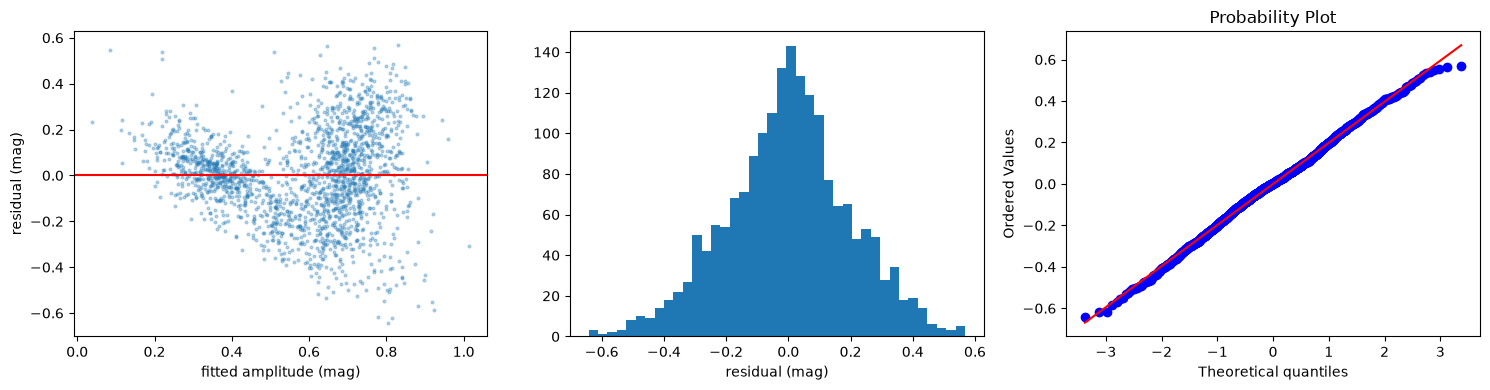

residual skewness: -0.072 | excess kurtosis: 0.038
Breusch-Pagan p: 5.1948221542432277e-45


In [6]:
from scipy import stats as st
res_ = fit.resid
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(fit.fittedvalues, res_, s=4, alpha=0.3)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("fitted amplitude (mag)")
ax[0].set_ylabel("residual (mag)")
ax[1].hist(res_, bins=40)
ax[1].set_xlabel("residual (mag)")
st.probplot(res_, dist="norm", plot=ax[2])
plt.tight_layout()
plt.show()

print("residual skewness:", round(st.skew(res_), 3), "| excess kurtosis:", round(st.kurtosis(res_), 3))
print("Breusch-Pagan p:", sm.stats.diagnostic.het_breuschpagan(res_, fit.model.exog)[1])

## 7. Interaction model with HC3 standard errors

In [7]:
d["log_period_x_overtone"] = d["log_period"] * d["overtone"]
preds2 = ["log_period", "bp_rp", "phot_g_mean_mag", "overtone", "log_period_x_overtone"]
fit2 = sm.OLS(d["peak_to_peak_g"], sm.add_constant(d[preds2])).fit()

print("R2 base:", round(fit.rsquared, 3), "| R2 interaction:", round(fit2.rsquared, 3))
print("adj R2 base:", round(fit.rsquared_adj, 3), "| interaction:", round(fit2.rsquared_adj, 3))
print()
print("Nested F-test (base vs interaction):")
print(sm.stats.anova_lm(fit, fit2))
print()
print(fit2.get_robustcov_results(cov_type="HC3").summary().tables[1])
print()
print("Breusch-Pagan p (interaction model):",
      sm.stats.diagnostic.het_breuschpagan(fit2.resid, fit2.model.exog)[1])

R2 base: 0.452 | R2 interaction: 0.492
adj R2 base: 0.451 | interaction: 0.491

Nested F-test (base vs interaction):
   df_resid        ssr  df_diff   ss_diff           F        Pr(>F)
0    1869.0  73.595133      0.0       NaN         NaN           NaN
1    1868.0  68.203775      1.0  5.391358  147.661283  9.351516e-33

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.5880      0.061      9.593      0.000       0.468       0.708
log_period               -1.7614      0.129    -13.641      0.000      -2.015      -1.508
bp_rp                    -0.0625      0.006     -9.879      0.000      -0.075      -0.050
phot_g_mean_mag          -0.0148      0.003     -5.246      0.000      -0.020      -0.009
overtone                  0.1646      0.049      3.394      0.001       0.070       0.260
log_period_x_overtone     1.8588      0.150     

## 8. Log-amplitude model (robustness check)

R2 (log amplitude): 0.479
Breusch-Pagan p: 2.7561841011846004e-10
residual skewness: -1.072 | excess kurtosis: 1.917

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -0.2193      0.050     -4.346      0.000      -0.318      -0.120
log_period               -1.2255      0.099    -12.433      0.000      -1.419      -1.032
bp_rp                    -0.0482      0.005     -8.850      0.000      -0.059      -0.037
phot_g_mean_mag          -0.0127      0.002     -5.431      0.000      -0.017      -0.008
overtone                  0.1744      0.053      3.301      0.001       0.071       0.278
log_period_x_overtone     1.4817      0.136     10.877      0.000       1.214       1.749


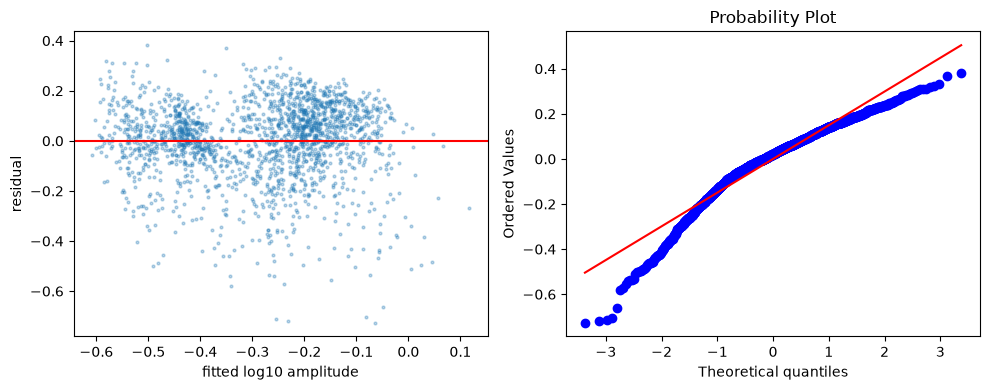

In [8]:
d["log_amp"] = np.log10(d["peak_to_peak_g"])
fit3 = sm.OLS(d["log_amp"], sm.add_constant(d[preds2])).fit()
print("R2 (log amplitude):", round(fit3.rsquared, 3))
print("Breusch-Pagan p:", sm.stats.diagnostic.het_breuschpagan(fit3.resid, fit3.model.exog)[1])
print("residual skewness:", round(st.skew(fit3.resid), 3), "| excess kurtosis:", round(st.kurtosis(fit3.resid), 3))
print()
print(fit3.get_robustcov_results(cov_type="HC3").summary().tables[1])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(fit3.fittedvalues, fit3.resid, s=4, alpha=0.3)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("fitted log10 amplitude")
ax[0].set_ylabel("residual")
st.probplot(fit3.resid, dist="norm", plot=ax[1])
plt.tight_layout()
plt.show()

## 9. Sensitivity check: G <= 18 (post-hoc)

In [ ]:
b = d[d["phot_g_mean_mag"] <= 18]
fitb = sm.OLS(b["peak_to_peak_g"], sm.add_constant(b[preds2])).fit()
print("n =", len(b), "| R2 =", round(fitb.rsquared, 3))
print("Breusch-Pagan p:", sm.stats.diagnostic.het_breuschpagan(fitb.resid, fitb.model.exog)[1])
print(fitb.get_robustcov_results(cov_type="HC3").summary().tables[1])

n = 862 | R2 = 0.558
Breusch-Pagan p: 1.3638369958051277e-19
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.2137      0.106      2.023      0.043       0.006       0.421
log_period               -2.1034      0.162    -13.014      0.000      -2.421      -1.786
bp_rp                    -0.0883      0.015     -5.838      0.000      -0.118      -0.059
phot_g_mean_mag           0.0052      0.006      0.807      0.420      -0.007       0.018
overtone                  0.2119      0.063      3.382      0.001       0.089       0.335
log_period_x_overtone     2.2332      0.188     11.853      0.000       1.863       2.603


## 10. One-sample t and Z tests

In [10]:
from stats_toolkit import one_sample_t, one_sample_z
from statsmodels.stats.weightstats import ztest

MU0 = 0.65  # illustrative benchmark (mag), not a literature value
f_amp = rr[(rr["period_type"] == "fundamental")]["peak_to_peak_g"].to_numpy()

print("Large sample: fundamental-mode amplitude, n =", len(f_amp), "| mean =", round(f_amp.mean(), 4))
for alt in ["two-sided", "greater", "less"]:
    t, df, p = one_sample_t(f_amp, MU0, alt)
    sp = stats.ttest_1samp(f_amp, MU0, alternative=alt)
    z, pz = one_sample_z(f_amp, MU0, alt)
    zs, pzs = ztest(f_amp, value=MU0, alternative={"two-sided": "two-sided", "greater": "larger", "less": "smaller"}[alt])
    print(f"{alt:10s} t={t:.3f} p={p:.3g} | scipy t={sp.statistic:.3f} p={sp.pvalue:.3g} | "
          f"Z={z:.3f} p={pz:.3g} | statsmodels Z={zs:.3f} p={pzs:.3g}")

rng = np.random.default_rng(42)
small = rng.choice(f_amp, size=15, replace=False)
t, df, p = one_sample_t(small, MU0)
z, pz = one_sample_z(small, MU0)
print()
print("Small sample (n = 15): mean =", round(small.mean(), 4))
print(f"t = {t:.3f} (df {df}), p = {p:.4f} | scipy p = {stats.ttest_1samp(small, MU0).pvalue:.4f} | Z p = {pz:.4f}")

Large sample: fundamental-mode amplitude, n = 1312 | mean = 0.6809
two-sided  t=4.279 p=2.01e-05 | scipy t=4.279 p=2.01e-05 | Z=4.279 p=1.88e-05 | statsmodels Z=4.279 p=1.88e-05
greater    t=4.279 p=1.01e-05 | scipy t=4.279 p=1.01e-05 | Z=4.279 p=9.39e-06 | statsmodels Z=4.279 p=9.39e-06
less       t=4.279 p=1 | scipy t=4.279 p=1 | Z=4.279 p=1 | statsmodels Z=4.279 p=1

Small sample (n = 15): mean = 0.6347
t = -0.234 (df 14), p = 0.8186 | scipy p = 0.8186 | Z p = 0.8152


## Summary (reproducible RR Lyrae sample, Gaia DR3, queried 2026-10-13)

- **Sample:** 2000 RR Lyrae (random_index < 20 million, ordered by random_index): 1312 fundamental-mode and 688 overtone. bp_rp is missing for 6.3%, so analyses using colour have n = 1874.
- **Pilot results reproduce.** Period vs amplitude: pooled r = +0.411 (95% CI 0.374 to 0.447), fundamental r = -0.411 (-0.455 to -0.365), overtone r = +0.222 (0.150 to 0.292). The pooled sign is the opposite of the fundamental-mode sign (Simpson's paradox). Within the fundamental mode, period explains about 17% of amplitude variation (r² = 0.169). Mean amplitude is 0.681 mag (fundamental) vs 0.354 mag (overtone), Welch t = 40.3.
- **Partial correlation** (period vs amplitude, controlling for G and bp_rp, n = 1874): pooled +0.390, fundamental -0.448, overtone +0.167. The sign pattern does not depend on brightness or colour. The hand-coded function matches the statsmodels route to six decimals.
- **Multiple regression** (amplitude ~ log period + bp_rp + G + overtone, n = 1874): R² = 0.452. VIFs are 4.91 (log period), 4.87 (overtone), 1.15 and 1.15, matching statsmodels. Log period and mode are nearly collinear, so their coefficients should be read together. Mode matters far more than colour or brightness.
- **Diagnostics:** residuals are close to normal (skewness -0.07, excess kurtosis 0.04), but variance is not constant (Breusch-Pagan p about 5e-45) and the residual plot is wedge-shaped.
- **Interaction model** (log period x mode, HC3 robust standard errors): R² = 0.492, nested F = 147.7, p about 9e-33. Fundamental-mode slope -1.761 (CI -2.015 to -1.508); overtone slope +0.097, essentially flat. Breusch-Pagan is still significant, so HC3 errors are used. The overtone main effect is evaluated at log period = 0, far outside the data, so it is not interpreted on its own.
- **Robustness (post-hoc):** a log10-amplitude model gives the same slope signs (fundamental -1.226, overtone +0.256) but its residuals are left-skewed (-1.07), so the raw-amplitude model is the main one. Restricting to G <= 18 (n = 862) gives R² = 0.558 and similar slopes (fundamental -2.103, overtone +0.130).
- **One-sample tests** (fundamental-mode amplitude vs an illustrative benchmark of 0.65 mag, not a literature value): n = 1312, mean 0.681, t = Z = 4.279, two-sided p = 2.0e-05, so the gap is significant mainly because n is large. A random sample of 15 (mean 0.635) gives t = -0.234, p = 0.819, which reflects low power, not agreement. Hand-coded t and Z match scipy and statsmodels.
- **Limitations:** associations in a catalogued sample, not causes. Colour is affected by dust and crowding. Class labels and periods come from Gaia's pipeline. Temperature, luminosity and radius were not pulled, so only colour and G stand in for stellar properties. The Cepheid sample was not repeated on a reproducible pull. A machine-learning extension (planned notebook 08) was left as future work.